# House Prices Valuation - Academic Audit & Consolidated ML Pipeline

## 1. Project Framing & Scope

### A. Business Problem Framing
* **Business Context:** Preliminary house-price estimations are required by a hypothetical real-estate analyst or valuation team to assist in preliminary assessments from observable housing characteristics.
* **Stakeholder:** Real-estate valuation team and analysts.
* **Primary Lens:** Predictive performance, primarily measured by Mean Absolute Error (MAE) in US Dollars ($).
* **Unit of Analysis:** One individual residential property.
* **Target Variable:** `SalePrice` (Continuous USD value).
* **Task:** Supervised Regression.
* **Required Output:** A single predicted sale price per property.
* **Practical Value:** Provides a consistent, repeatable benchmark to support property pricing analysis, comparative market analysis, and preliminary valuation workflows.
* **Boundaries & Limitations:** This model serves as a preliminary evaluation tool. It is not a formal property appraisal and is not guaranteed to generalize to other geographical locations or future markets.

---

### B. Project Workflow Diagram
```
Business Problem → Data Loading → One Development/Holdout Split (Seed 42) → EDA (Dev Only) → Feature Engineering and Preprocessing → Model Comparison Tournament → Hyperparameter Tuning (GridSearchCV) → Untouched Holdout Evaluation → Residual Analysis → Production Refit & Serialization
```

---

### C. Scope and Validation Policy
* **Kaggle Train Dataset (`train.csv`):** Contains the labelled examples used exclusively for developing, cross-validating, and testing our model's performance internally.
* **Kaggle Test Dataset (`test.csv`):** Used solely for generating final unlabelled predictions for submission.
* **Internal Validation Splitting:**
  * **Development Partition (`X_dev`, `y_dev`):** 80% of the training dataset. Used for all exploratory diagnostics, feature-engineering validation, model tournament, and hyperparameter tuning.
  * **Shuffled 5-Fold Cross-Validation:** Applied strictly on the development partition to guide architectural decisions without leakages.
  * **Holdout Partition (`X_holdout`, `y_holdout`):** 20% of the training dataset. Remains completely untouched throughout development and is used strictly once at the end to evaluate generalization performance.

* **Historical Exposure Disclosure:**
  * Earlier notebook versions inspected and reused these labelled observations, including the current holdout. This repair enforces separation in the corrected execution, but it cannot erase that historical exposure. Report the repaired internal holdout result with this limitation; a genuinely fresh external evaluation would require previously unused labelled data.

In [1]:
import os
import sys
import hashlib
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.feature_selection import SelectFromModel, SelectPercentile, mutual_info_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone

# System reproducible seed
np.random.seed(42)

train_path = '/content/train.csv'
test_path = '/content/test.csv'

if not os.path.exists(train_path) or not os.path.exists(test_path):
    raise FileNotFoundError("Mandatory dataset files train.csv or test.csv could not be found.")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

assert 'SalePrice' in train_df.columns, "Training data is missing target 'SalePrice'"
assert 'Id' in train_df.columns, "Training data is missing 'Id'"
assert 'Id' in test_df.columns, "Test data is missing 'Id'"
assert 'SalePrice' not in test_df.columns, "Test data must not contain 'SalePrice'"

train_cols = set(train_df.columns) - {'SalePrice', 'Id'}
test_cols = set(test_df.columns) - {'Id'}
assert train_cols == test_cols, "Predictor columns do not match between train and test datasets."

target_col_order = list(train_df.drop(columns=['SalePrice', 'Id']).columns)
test_df_aligned = test_df[['Id'] + target_col_order]

y = train_df['SalePrice'].copy()
X = train_df.drop(columns=['SalePrice', 'Id'])
X_test_kaggle = test_df_aligned.drop(columns=['Id'])

# System & Pipeline split setup
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
dev_df = train_df.loc[X_dev.index].copy()

assert X_dev.index.intersection(X_holdout.index).empty
assert len(X_dev) + len(X_holdout) == len(X)
assert X_dev.index.equals(y_dev.index)
assert X_holdout.index.equals(y_holdout.index)
assert train_df['Id'].is_unique and test_df['Id'].is_unique
assert np.isfinite(y.to_numpy()).all()

na_meaningful_cols = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType'
]

try:
    import xgboost as xgb
    has_xgb = True
except ImportError:
    raise ImportError("XGBoost library is mandatory and must be installed for comparisons.")

holdout_evaluated = False

def get_sha256(filepath):
    sha256_hash = hashlib.sha256()
    with open(filepath, 'rb') as f:
        for byte_block in iter(lambda: f.read(4096), b''):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

print("=== SYSTEM & PIPELINE PROVENANCE ===")
print(f"Python Version: {sys.version}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"SHA-256 (train.csv): {get_sha256(train_path)}")
print(f"SHA-256 (test.csv): {get_sha256(test_path)}")
print(f"Development set shape (80%): {X_dev.shape}")
print(f"Holdout set shape (20%): {X_holdout.shape}")

=== SYSTEM & PIPELINE PROVENANCE ===
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-Learn Version: 1.6.1
SHA-256 (train.csv): 1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41
SHA-256 (test.csv): 8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e
Development set shape (80%): (1168, 79)
Holdout set shape (20%): (292, 79)


## 2. Programmatic Data Dictionary & Exploratory Data Diagnostics (Development Partition Only)

To ensure complete methodological integrity and prevent any test/holdout contamination, all statistical checks, target distributions, and feature correlations are evaluated strictly on the **Development Partition (`X_dev`, `y_dev`)**.

In [2]:
# Programmatically generate data dictionary statistics on X_dev
missing_counts = X_dev.isnull().sum()
missing_pct = (X_dev.isnull().sum() / len(X_dev)) * 100
cardinality = X_dev.nunique()

columns_list = []
for col in X_dev.columns:
    role = 'Predictor'
    if col == 'MSSubClass':
        strategy = 'Categorical (One-Hot)'
    elif X_dev[col].dtype == 'object':
        if col in na_meaningful_cols:
            strategy = "Constant 'None' Impute (Structural Absence) + One-Hot"
        else:
            strategy = "Most Frequent Impute + One-Hot"
    else:
        strategy = "Median Impute"

    columns_list.append({
        'Column Name': col,
        'Data Type': str(X_dev[col].dtype),
        'Role': role,
        'Missing Count': missing_counts[col],
        'Missing %': f"{missing_pct[col]:.2f}%",
        'Unique Values': cardinality[col],
        'Processing Strategy': strategy
    })

data_dict_df = pd.DataFrame(columns_list)
pd.set_option('display.max_rows', 100)
print("=== DEVELOPMENT PROGRAMMATIC DATA DICTIONARY ===")
display(data_dict_df.head(20))

=== DEVELOPMENT PROGRAMMATIC DATA DICTIONARY ===


,Column Name,Data Type,Role,Missing Count,Missing %,Unique Values,Processing Strategy
0,MSSubClass,int64,Predictor,0,0.00%,15,Categorical (One-Hot)
1,MSZoning,object,Predictor,0,0.00%,5,Most Frequent Impute + One-Hot
2,LotFrontage,float64,Predictor,217,18.58%,107,Median Impute
3,LotArea,int64,Predictor,0,0.00%,890,Median Impute
4,Street,object,Predictor,0,0.00%,2,Most Frequent Impute + One-Hot
5,Alley,object,Predictor,1094,93.66%,2,Constant 'None' Impute (Structural Absence) + ...
6,LotShape,object,Predictor,0,0.00%,4,Most Frequent Impute + One-Hot
7,LandContour,object,Predictor,0,0.00%,4,Most Frequent Impute + One-Hot
8,Utilities,object,Predictor,0,0.00%,2,Most Frequent Impute + One-Hot
9,LotConfig,object,Predictor,0,0.00%,5,Most Frequent Impute + One-Hot


In [3]:
display(dev_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1168 entries, 254 to 1126
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   object 
 3   LotFrontage    951 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   object 
 6   Alley          74 non-null     object 
 7   LotShape       1168 non-null   object 
 8   LandContour    1168 non-null   object 
 9   Utilities      1168 non-null   object 
 10  LotConfig      1168 non-null   object 
 11  LandSlope      1168 non-null   object 
 12  Neighborhood   1168 non-null   object 
 13  Condition1     1168 non-null   object 
 14  Condition2     1168 non-null   object 
 15  BldgType       1168 non-null   object 
 16  HouseStyle     1168 non-null   object 
 17  OverallQual    1168 non-null   int64  
 18  OverallCond

None

### Statistical Summary of Development Partition

In [4]:
display(dev_df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1168.000000,1168.000000,951.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1162.000000,1168.000000,...,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,730.904966,56.849315,70.343849,10689.642123,6.121575,5.584760,1970.965753,1984.897260,103.771945,446.023973,...,95.946918,49.578767,21.839041,3.812500,15.407534,2.955479,51.267123,6.356164,2007.818493,181441.541952
std,425.369088,42.531862,24.897021,10759.366198,1.367619,1.116062,30.675495,20.733955,173.032238,459.070977,...,129.685939,69.433580,62.083227,31.519664,55.881148,41.648504,553.039684,2.670707,1.322639,77263.583862
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.750000,20.000000,59.000000,7587.250000,5.000000,5.000000,1953.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130000.000000
50%,732.500000,50.000000,70.000000,9600.000000,6.000000,5.000000,1972.000000,1994.000000,0.000000,384.500000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165000.000000
75%,1101.750000,70.000000,80.000000,11700.000000,7.000000,6.000000,2001.000000,2004.000000,166.000000,721.000000,...,168.000000,74.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214925.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1378.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,745000.000000


### Missing Values and Duplicates on Development Partition

In [5]:
print("Missing values in train development partition:")
dev_missing = dev_df.isnull().sum()
display(dev_missing[dev_missing > 0])
print(f"\nNumber of duplicate rows in development partition: {dev_df.drop(columns=['Id']).duplicated().sum()}")

Missing values in train development partition:


,0
LotFrontage,217
Alley,1094
MasVnrType,683
MasVnrArea,6
BsmtQual,28
BsmtCond,28
BsmtExposure,28
BsmtFinType1,28
BsmtFinType2,28
Electrical,1



Number of duplicate rows in development partition: 0


### Target Variable Analysis (y_dev)

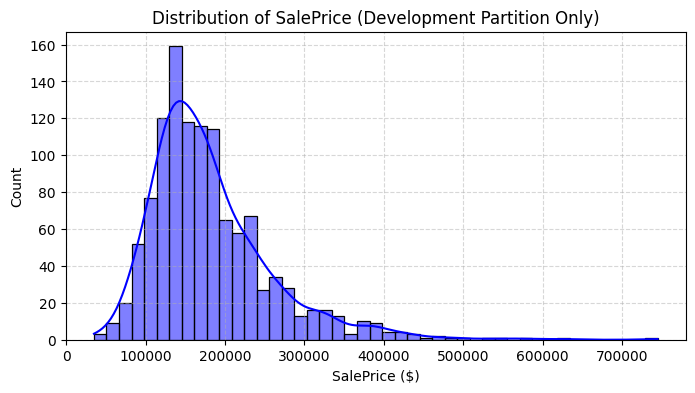

Skewness (y_dev): 1.7431
Kurtosis (y_dev): 5.4753


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(y_dev, kde=True, color='blue')
plt.title('Distribution of SalePrice (Development Partition Only)')
plt.xlabel('SalePrice ($)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Skewness (y_dev): {y_dev.skew():.4f}")
print(f"Kurtosis (y_dev): {y_dev.kurt():.4f}")

### Feature Correlation strictly on Development Partition

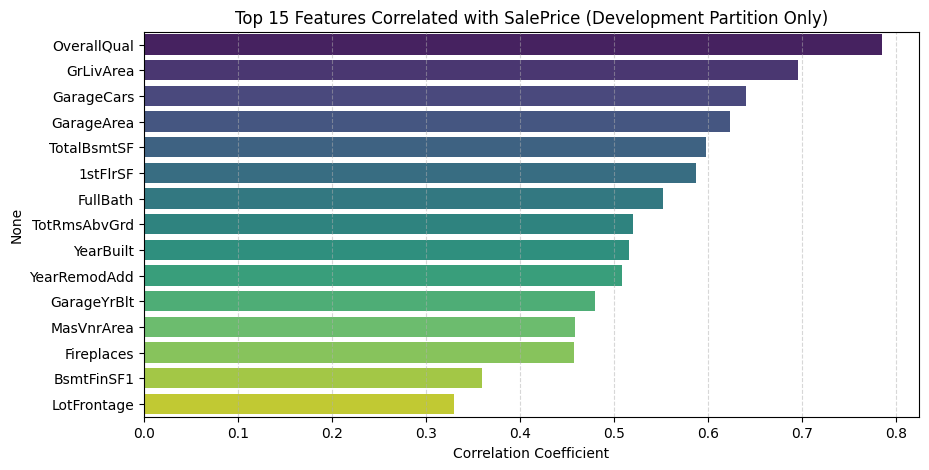

In [7]:
numeric_X_dev = X_dev.select_dtypes(include=['int64', 'float64']).copy()
numeric_X_dev['SalePrice'] = y_dev

corr_matrix = numeric_X_dev.corr()
top_corr_features = corr_matrix['SalePrice'].drop('SalePrice').sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_corr_features.values, y=top_corr_features.index, hue=top_corr_features.index, palette='viridis', legend=False)
plt.title('Top 15 Features Correlated with SalePrice (Development Partition Only)')
plt.xlabel('Correlation Coefficient')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.show()